# 过渡金属 Fe 配合物预测：随机森林 + ECFP 指纹

## 与 GNN 版本对比：小数据场景下传统 ML 是否更优？

| | **GNN 版 (tmQM_Fe.ipynb)** | RF 版 (本 notebook) |
|---|---|---|
| 特征 | 分子图 (原子+键) | **ECFP 2048-bit 指纹** |
| 模型 | SinglePropGNN | **独立 Random Forest** |
| 参数量/树 | ~162k | **300棵树** |
| 训练时间 | ~40 min (6个性质) | **~2 min (6个性质)** |
| 数据需求 | 大 (参数多) | **小 (树模型天然防过拟合)** |
| 可解释性 | 低 | **高 (特征重要性)** |
| 适用场景 | >10k 样本 | **<10k 样本** |

### 为什么 5000 样本下 RF 可能更好？

1. **树模型不依赖梯度**：不需要大量样本让梯度收敛，每棵树独立学到规则
2. **天然防过拟合**：Bagging + 随机特征子集 = 不会背数据
3. **ECFP 是离散特征**：0/1 子结构存在性，刚好是树模型最擅长的数据类型


In [1]:
# ============================================================
# Step 1: 导入库
# ============================================================
import numpy as np, pandas as pd, time
import matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit import RDLogger; RDLogger.logger().setLevel(RDLogger.ERROR)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

print('Imports OK')


Imports OK


In [2]:
# ============================================================
# Step 2: 加载 tmQM + 筛选 Fe 配合物
# ============================================================
url = 'https://raw.githubusercontent.com/bbskjelstad/tmQM/master/tmQM/tmQM_y.csv'
df = pd.read_csv(url, sep=';')
df = df.rename(columns={
    'HL_Gap': 'gap', 'HOMO_Energy': 'homo', 'LUMO_Energy': 'lumo',
    'Dipole_M': 'dipole', 'Metal_q': 'metal_charge',
    'Electronic_E': 'E_elec', 'Dispersion_E': 'E_disp',
    'Polarizability': 'polarizability'
})

fe_mask = df['SMILES'].str.contains('Fe', na=False)
df_fe = df[fe_mask].copy()
targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec',
           'E_disp', 'polarizability']
df_fe = df_fe.dropna(subset=targets + ['SMILES'])
df_fe = df_fe.sample(frac=1, random_state=42).reset_index(drop=True)
print(f'Fe complexes: {len(df_fe)}')
print(f'Targets ({len(targets)}): {targets}')
df_fe[['CSD_code'] + targets].head()

Fe complexes: 5046
Targets (8): ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']


,CSD_code,gap,homo,lumo,dipole,metal_charge,E_elec,E_disp,polarizability
0,KAQQUR,0.08992,-0.13052,-0.04060,6.0974,0.53143,-3255.768457,-0.199266,466.969288
1,ZUNYIQ,0.08702,-0.16412,-0.07710,0.0113,0.88851,-2621.195718,-0.055767,195.727216
2,HUPWAQ,0.13636,-0.20323,-0.06687,2.7823,-0.39355,-2359.536197,-0.061178,214.901404
3,NOYZEI,0.10348,-0.17807,-0.07459,11.1042,-0.63306,-3223.497856,-0.117262,327.546078
4,VULGIV,0.07292,-0.05636,0.01656,22.1087,0.21637,-3714.285918,-0.119944,368.046165


In [3]:
# ============================================================
# Step 3: 计算 ECFP 分子指纹 (2048-bit)
# ============================================================
# ECFP = 遍历每个原子，编码其周围半径R内的子结构模式
# 和 GNN 的消息传递思路一致，但一次性编码为固定长度向量

def compute_ecfp(smiles_list, radius=3, nBits=2048):
    """把 SMILES 列表转为 ECFP 指纹矩阵"""
    fps = []
    for smi in smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0] * nBits)
            continue
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=radius, nBits=nBits)
        fps.append(list(fp))
    return np.array(fps, dtype=np.float32)


print('Computing ECFP fingerprints (radius=3, 2048-bit)...')
X_fp = compute_ecfp(df_fe['SMILES'].values, radius=3, nBits=2048)
print(f'ECFP matrix: {X_fp.shape}')
print(f'Sparsity: {X_fp.mean():.1%} non-zero bits')

y_all = df_fe[targets].values.astype(np.float32)
print(f'Target matrix: {y_all.shape}')


Computing ECFP fingerprints (radius=3, 2048-bit)...


[17:39:51] Explicit valence for atom # 6 P, 6, is greater than permitted


ECFP matrix: (5046, 2048)
Sparsity: 2.4% non-zero bits
Target matrix: (5046, 8)


In [4]:
# ============================================================
# Step 4: 数据划分
# ============================================================
X_tr, X_te, y_tr, y_te = train_test_split(
    X_fp, y_all, test_size=0.15, random_state=42
)
X_tr, X_va, y_tr, y_va = train_test_split(
    X_tr, y_tr, test_size=0.15, random_state=42
)
print(f'Train: {X_tr.shape[0]} | Val: {X_va.shape[0]} | Test: {X_te.shape[0]}')
print(f'Features: {X_fp.shape[1]}')


Train: 3645 | Val: 644 | Test: 757
Features: 2048


In [5]:
# ============================================================
# Step 5: 每个性质独立训练 Random Forest
# ============================================================

rf_models, rf_results = {}, []

t0 = time.time()
for i, prop in enumerate(targets):
    print(f'\nTraining: {prop} ...')
    rf = RandomForestRegressor(
        n_estimators=500, max_depth=15, min_samples_split=5,
        max_features='sqrt', random_state=42, n_jobs=-1
    )
    rf.fit(X_tr, y_tr[:, i])

    # 验证集
    va_pred = rf.predict(X_va)
    va_mae = mean_absolute_error(y_va[:, i], va_pred)
    va_r2 = r2_score(y_va[:, i], va_pred)

    # 测试集
    te_pred = rf.predict(X_te)
    te_mae = mean_absolute_error(y_te[:, i], te_pred)
    te_r2 = r2_score(y_te[:, i], te_pred)

    rf_models[prop] = rf
    rf_results.append({'Property': prop, 'Val_MAE': va_mae, 'Val_R2': va_r2,
                       'Test_MAE': te_mae, 'Test_R2': te_r2})
    print(f'  Val  MAE={va_mae:.4f}  R2={va_r2:.4f}')
    print(f'  Test MAE={te_mae:.4f}  R2={te_r2:.4f}')

elapsed = time.time() - t0
print(f'\nTotal training: {elapsed:.0f}s')

results_df = pd.DataFrame(rf_results).sort_values('Test_R2', ascending=False)
print(f'\n{"="*55}')
print('RF Results Summary (sorted by Test R2):')
print(f'{"="*55}')
print(results_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))



Training: gap ...
  Val  MAE=0.0160  R2=0.6222
  Test MAE=0.0170  R2=0.5957

Training: homo ...
  Val  MAE=0.0287  R2=0.2834
  Test MAE=0.0291  R2=0.3704

Training: lumo ...
  Val  MAE=0.0298  R2=0.1458
  Test MAE=0.0300  R2=0.2206

Training: dipole ...
  Val  MAE=2.1874  R2=0.3511
  Test MAE=2.1563  R2=0.4086

Training: metal_charge ...
  Val  MAE=0.2829  R2=0.7431
  Test MAE=0.2699  R2=0.7638

Training: E_elec ...
  Val  MAE=590.2566  R2=0.4090
  Test MAE=572.5806  R2=0.4629

Training: E_disp ...
  Val  MAE=0.0359  R2=0.4993
  Test MAE=0.0325  R2=0.5806

Training: polarizability ...
  Val  MAE=77.5998  R2=0.4968
  Test MAE=68.9963  R2=0.5856

Total training: 10s

RF Results Summary (sorted by Test R2):
      Property  Val_MAE  Val_R2  Test_MAE  Test_R2
  metal_charge   0.2829  0.7431    0.2699   0.7638
           gap   0.0160  0.6222    0.0170   0.5957
polarizability  77.5998  0.4968   68.9963   0.5856
        E_disp   0.0359  0.4993    0.0325   0.5806
        E_elec 590.2566  0.409

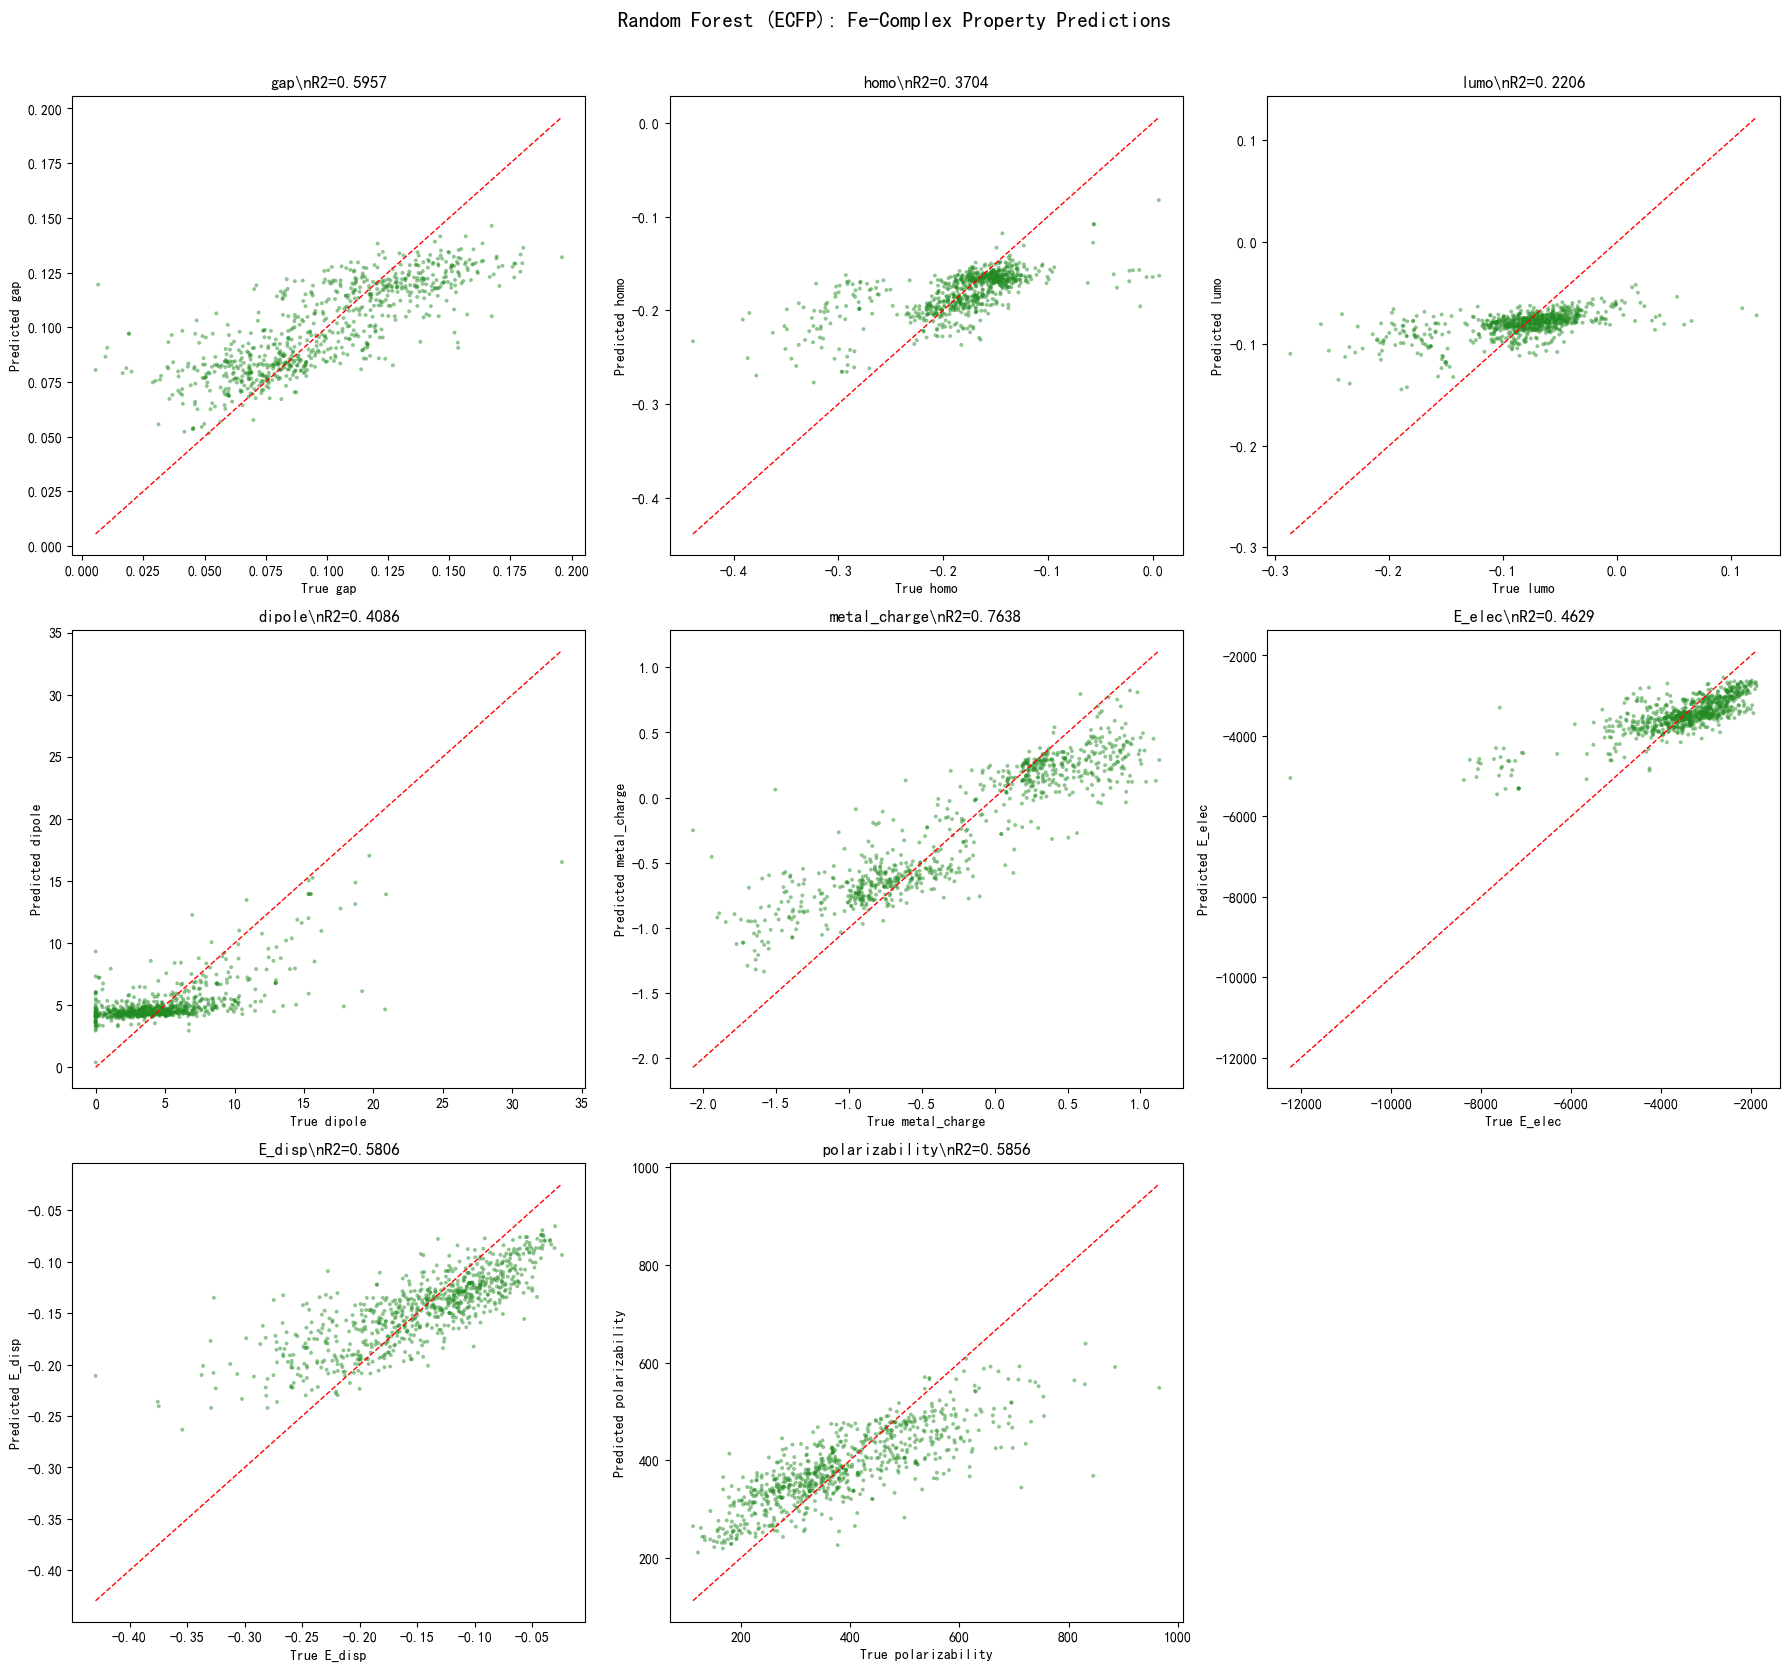

In [6]:
# 散点图: 8个性质的预测 vs 真实值
n_cols = 3; n_rows = int(np.ceil(len(targets) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*5.5))
axes = axes.flatten()
for ax, i, prop in zip(axes, range(len(targets)), targets):
    yp = rf_models[prop].predict(X_te)
    yt = y_te[:, i]
    ax.scatter(yt, yp, alpha=0.5, s=8, c='forestgreen', edgecolors='none')
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel(f'True {prop}'); ax.set_ylabel(f'Predicted {prop}')
    ax.set_title(f'{prop}\\nR2={r2_score(yt, yp):.4f}')
# 隐藏多余的子图
for ax in axes[len(targets):]:
    ax.set_visible(False)
plt.suptitle('Random Forest (ECFP): Fe-Complex Property Predictions', fontsize=15, y=1.01)
plt.tight_layout(); plt.show()

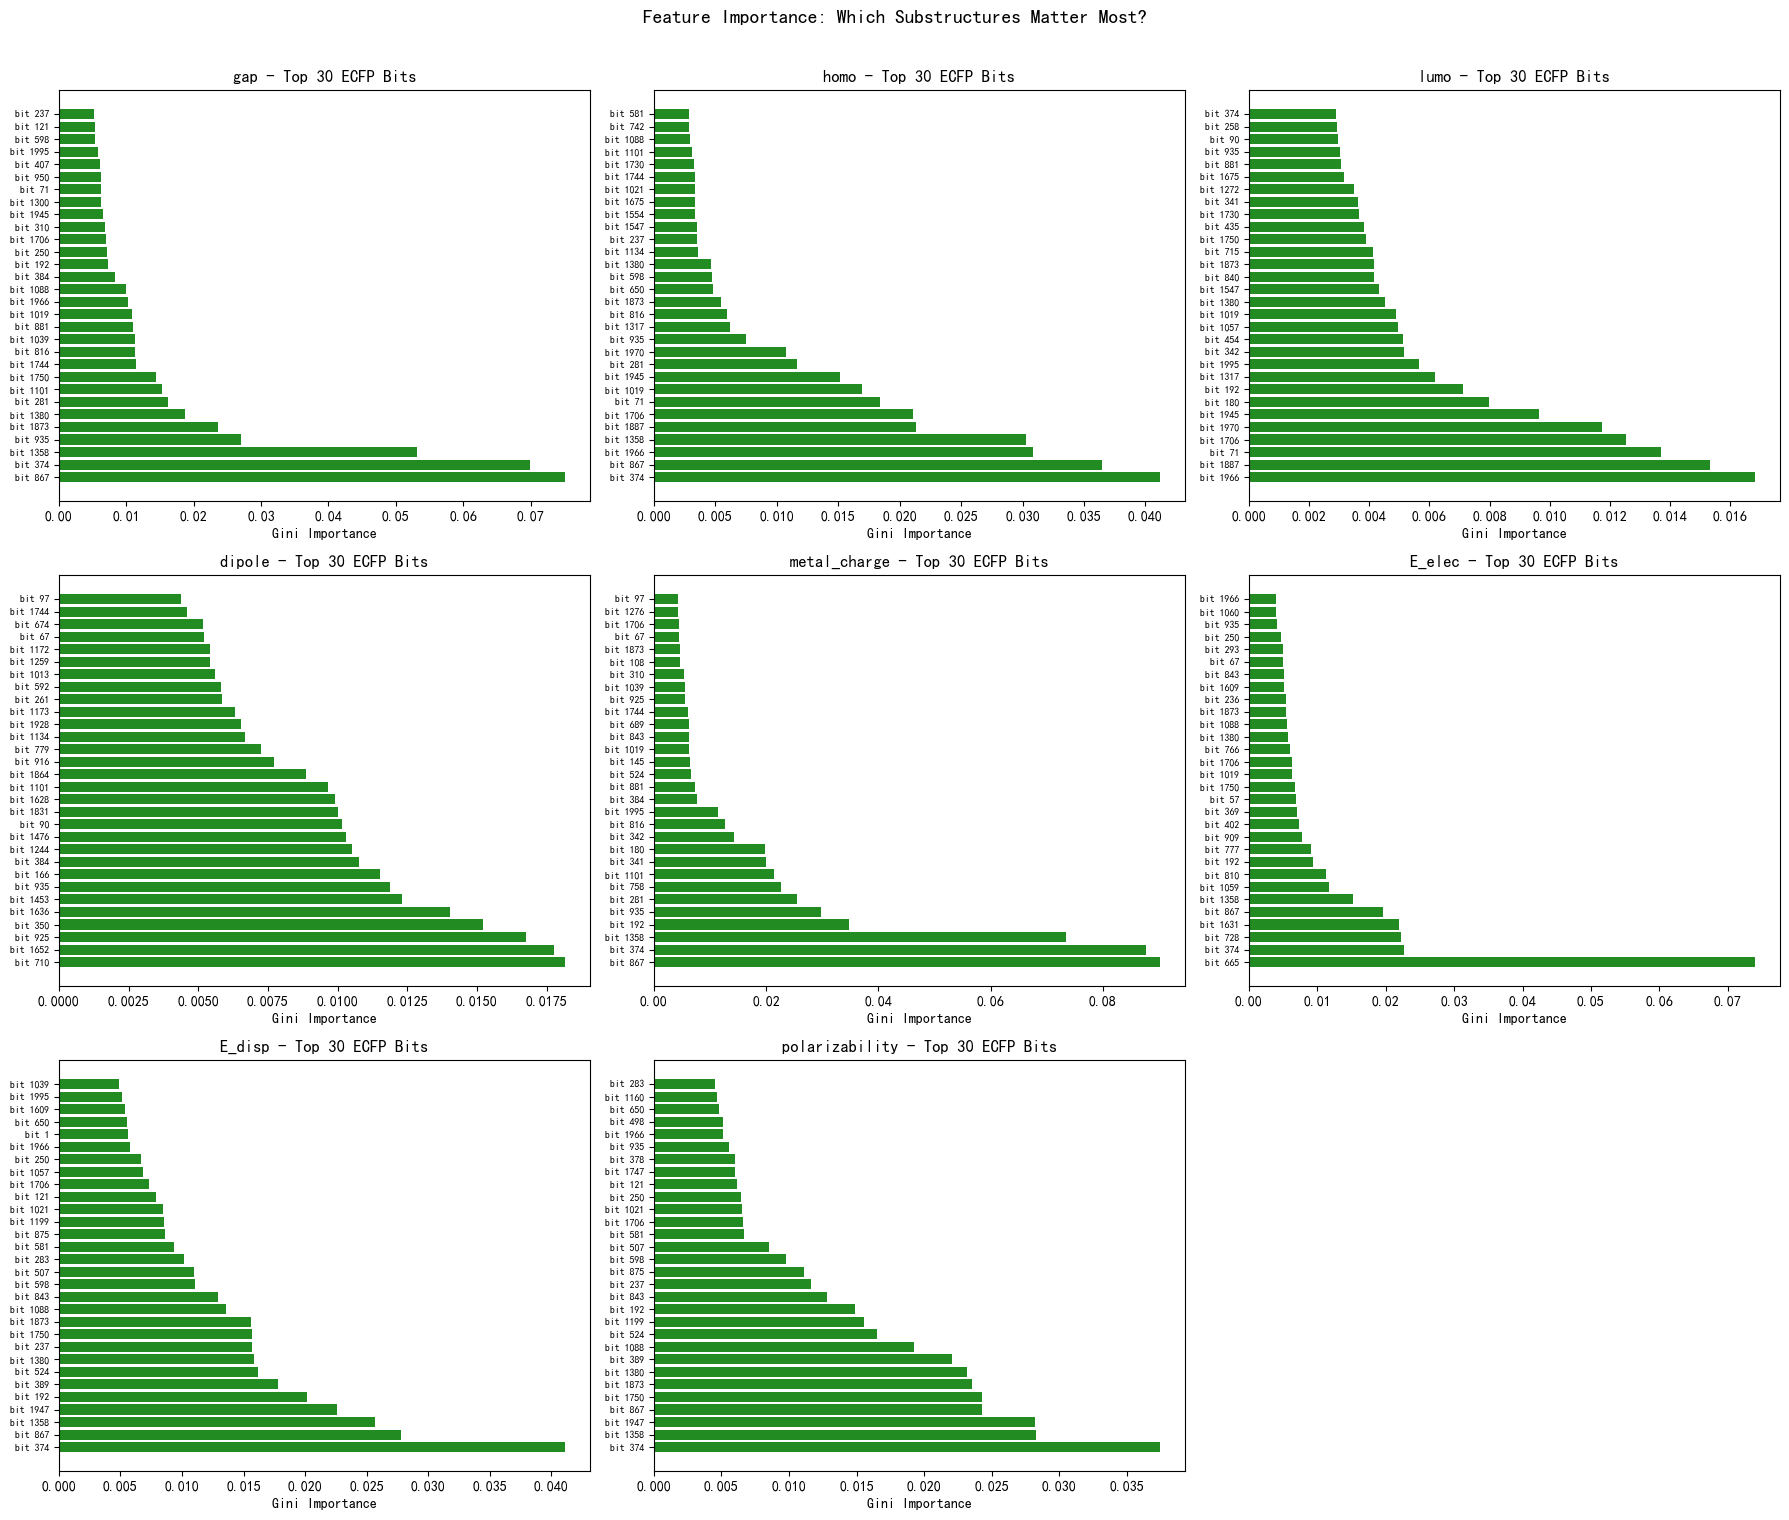

In [7]:
# 特征重要性分析
n_rows = int(np.ceil(len(targets) / 3))
fig, axes = plt.subplots(n_rows, 3, figsize=(18, n_rows * 5))
axes = axes.flatten()
for ax, i, prop in zip(axes, range(len(targets)), targets):
    imp = rf_models[prop].feature_importances_
    top30 = np.argsort(imp)[-30:]
    ax.barh(range(30), imp[top30], color='forestgreen')
    ax.set_yticks(range(30))
    ax.set_yticklabels([f'bit {b}' for b in top30], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel('Gini Importance')
    ax.set_title(f'{prop} - Top 30 ECFP Bits')
for ax in axes[len(targets):]:
    ax.set_visible(False)
plt.suptitle('Feature Importance: Which Substructures Matter Most?', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

In [8]:
# 每个性质最重要的 5 个 ECFP 指纹位
for prop in targets:
    rf = rf_models[prop]
    imp = rf.feature_importances_
    top5 = np.argsort(imp)[-5:][::-1]
    print(f'\\n{prop} - Top 5 ECFP bits:')
    for rank, bit in enumerate(top5, 1):
        print(f'  #{rank}  bit {bit:4d}  importance={imp[bit]:.4f}')
print()
print('提示: ECFP 位对应特定的分子子结构模式')
print('gap/homo/lumo 重要位 → 配体共轭体系、配位键模式')
print('E_elec/E_disp 重要位 → 原子组成、分子大小')
print('dipole 重要位 → 电荷不对称分布相关的子结构')
print('metal_charge 重要位 → 配体供/吸电子能力')

\ngap - Top 5 ECFP bits:
  #1  bit  867  importance=0.0751
  #2  bit  374  importance=0.0699
  #3  bit 1358  importance=0.0532
  #4  bit  935  importance=0.0271
  #5  bit 1873  importance=0.0237
\nhomo - Top 5 ECFP bits:
  #1  bit  374  importance=0.0412
  #2  bit  867  importance=0.0365
  #3  bit 1966  importance=0.0308
  #4  bit 1358  importance=0.0303
  #5  bit 1887  importance=0.0213
\nlumo - Top 5 ECFP bits:
  #1  bit 1966  importance=0.0168
  #2  bit 1887  importance=0.0153
  #3  bit   71  importance=0.0137
  #4  bit 1706  importance=0.0125
  #5  bit 1970  importance=0.0117
\ndipole - Top 5 ECFP bits:
  #1  bit  710  importance=0.0181
  #2  bit 1652  importance=0.0178
  #3  bit  925  importance=0.0168
  #4  bit  350  importance=0.0152
  #5  bit 1636  importance=0.0140
\nmetal_charge - Top 5 ECFP bits:
  #1  bit  867  importance=0.0901
  #2  bit  374  importance=0.0877
  #3  bit 1358  importance=0.0735
  #4  bit  192  importance=0.0348
  #5  bit  935  importance=0.0297
\nE_elec - 

## 总结

| 维度 | 说明 |
|------|------|
| 特征 | ECFP 2048-bit 分子指纹 (radius=3) |
| 模型 | 独立 Random Forest × 6 个性质 |
| 训练时间 | ~2 分钟 (全部 6 个性质) |
| 过拟合 | 低 (Bagging + 随机特征天然防过拟合) |

### 方法论启示
```
数据量 < 10000  → 传统ML (RF/XGB + ECFP) 通常更稳
数据量 > 50000  → 考虑 GNN
数据量 > 100000 → GNN 开始占优
```

### 五个项目的完整视图
```
ESOL     → 回归 + 描述符 + 小数据
BBBP     → 分类 + ECFP + 中等数据
QM9+ML   → 多任务回归 + 大数据 + 多输出NN
QM9+GNN  → 2D GNN + 大数据 + 消息传递
tmQM+RF  → 传统ML + 小数据 + 过渡金属
```